Importing Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [3]:
@jit(nopython=True)
def Pressure(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def chemical_potential(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def energy_density(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

constructing EoS :

In [16]:
# Initial Values :

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
K_had = 17906.60
m0_had = 939.56

pressure_transition = 63.177
energy_density_transition = 318.26
energy_density_transition_jump = 253.89
energy_density_quark = energy_density_transition + energy_density_transition_jump

n_quark = np.linspace(0.5344,1,1000)
Gam_quark = 2.5
K_quark = pressure_transition / (n_quark[0] ** Gam_quark)
m0_quark = (energy_density_quark - (K_quark * (n_quark[0] ** Gam_quark)) / (Gam_quark - 1)) / n_quark[0]

n_total = np.linspace(0.16,1,2000)

EoS Hadronic

In [17]:
pressure_had = Pressure(n_total, K_had, Gam_had)
chemical_potential_had = chemical_potential(n_total, K_had, Gam_had, m0_had)
energy_density_had = energy_density(n_total, K_had, Gam_had, m0_had)

EoS Quark

In [18]:
pressure_quark = Pressure(n_total, K_quark, Gam_quark)
chemical_potential_quark = chemical_potential(n_total, K_quark, Gam_quark, m0_quark)
energy_density_quark = energy_density(n_total, K_quark, Gam_quark, m0_quark)

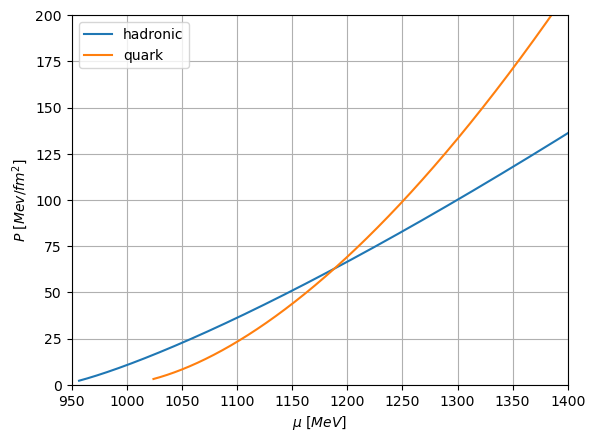

In [19]:
plt.plot(chemical_potential_had, pressure_had, label = "hadronic")
plt.plot(chemical_potential_quark,pressure_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [20]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (chemical_potential_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

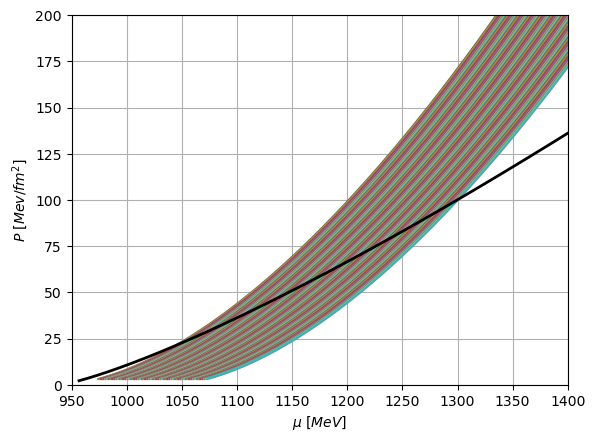

In [21]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], pressure_quark, label=f"quark set {i+1}")

plt.plot(chemical_potential_had, pressure_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()

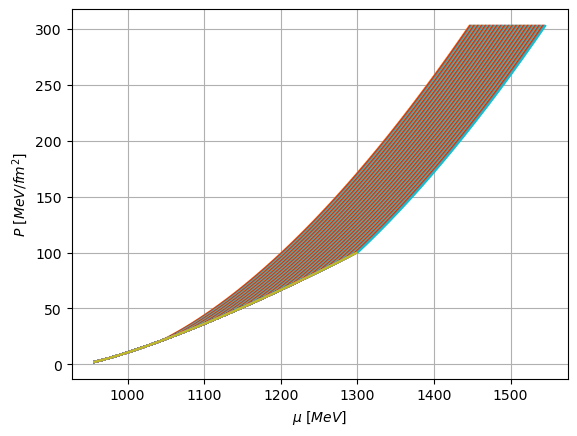

In [22]:
x1 = np.array(chemical_potential_had)
y1 = np.array(pressure_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves_quark, combined_mu_curves_had = [], []
combined_P_curves_quark, combined_P_curves_had = [], []
P_crit = []
mu_crit = []

combined_mu_curves, combined_p_curves = [], []

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(pressure_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest]
    P_had = y1[:index_had_closest]
    mu_quark_2 = x2[index_quark_closest:]
    P_quark_2 = y2[index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    combined_mu_curves.append(combined_mu)
    combined_p_curves.append(combined_P)

    # Store the combined curves in the list
    combined_mu_curves_quark.append(mu_quark_2)
    combined_P_curves_quark.append(P_quark_2)

    # Store the combined curves in the list
    combined_mu_curves_had.append(mu_had_1)
    combined_P_curves_had.append(P_had)

# Plot the combined curves
for i in range(len(combined_mu_curves_had)):
    plt.plot(combined_mu_curves_had[i], combined_P_curves_had[i], label=f"Combined Curve {i+1}")
    plt.plot(combined_mu_curves_quark[i], combined_P_curves_quark[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [29]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []
combined_cs2_11 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    # Compute the gradient of P with respect to mu
    gradient_1 = np.gradient(P_curve_1, mu_curve_1)
    gradient_2 = np.gradient(P_curve_2, mu_curve_2)

    e_curve_1 = (gradient_1*mu_curve_1)-P_curve_1
    cs2_1 = np.gradient(P_curve_1,e_curve_1)

    e_curve_2 = (gradient_2*mu_curve_2)-P_curve_2
    cs2_2 = np.gradient(P_curve_2,e_curve_2)

    combined_n.append(np.concatenate((gradient_1,gradient_2)))
    combined_e.append(np.concatenate((e_curve_1,e_curve_2)))
    combined_cs2.append(np.concatenate((cs2_1,cs2_2)))
    combined_p_1.append(np.concatenate((P_curve_1,P_curve_2)))
    combined_mu_1.append(np.concatenate((mu_curve_1,mu_curve_2)))


    cs2_11 = np.gradient(np.concatenate((P_curve_1,P_curve_2)),np.concatenate((e_curve_1,e_curve_2)))
    combined_cs2_11.append(cs2_11)


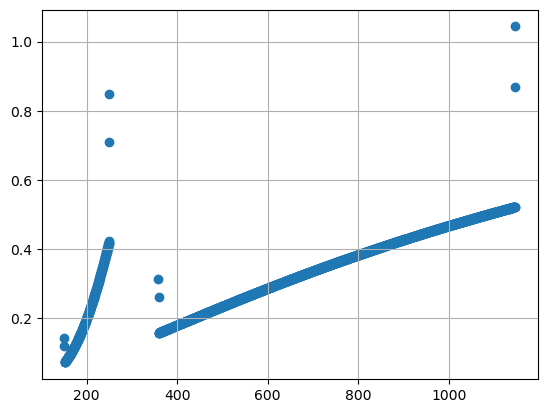

In [34]:
plt.scatter(combined_e[3],combined_cs2_11[3])

plt.grid()
plt.show()

In [30]:
e_total, p_total, mu_total, cs_total = combined_e, combined_p_1, combined_mu_1, combined_cs2_11

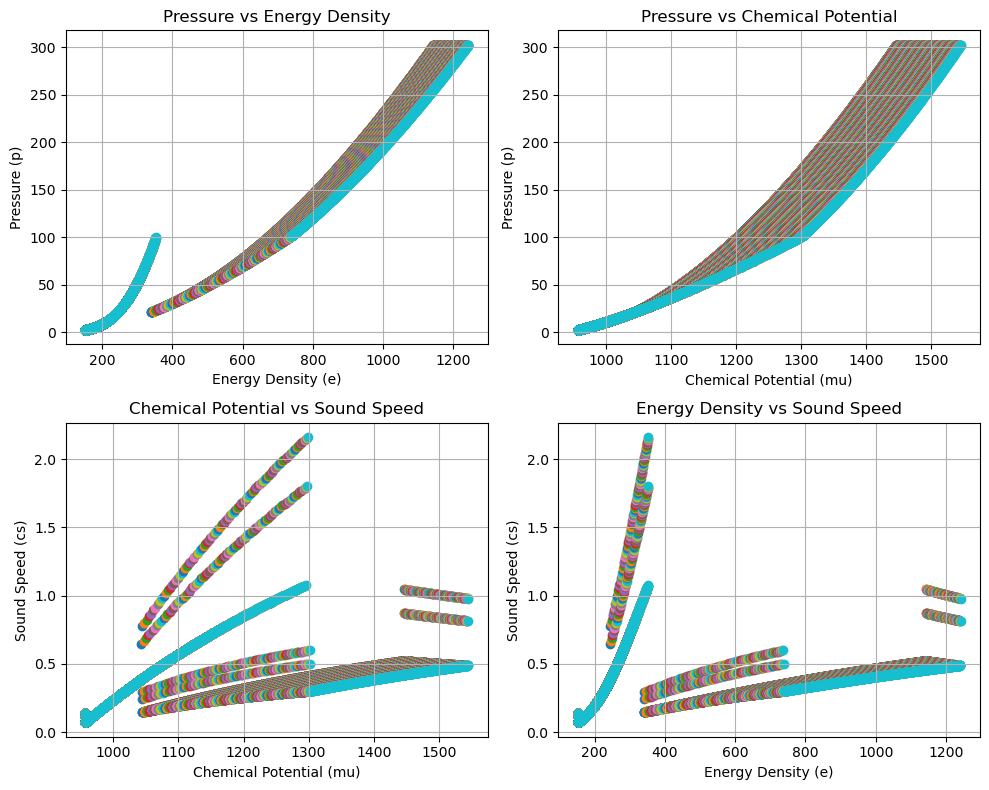

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].scatter(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].scatter(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].scatter(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [35]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    min_distance_points = np.array(min_distance_points)


    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index])
        P_all_1.append(P_optimal[0])
        P_max_points.append(min_distance_points[index])
        P_max_points_1.append(min_distance_points[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)

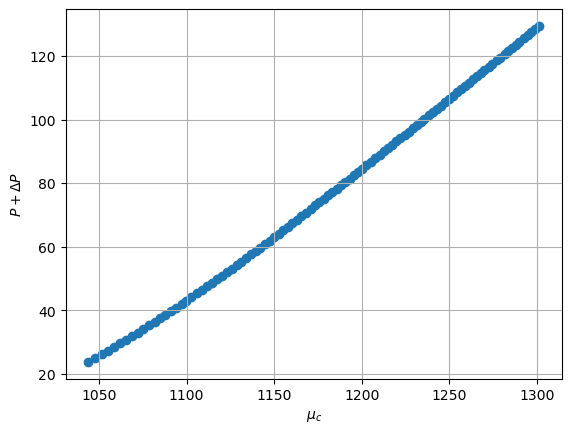

In [39]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();